In [2]:
from dataloader import load_all_data
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [3]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = {
    'pointwise':        'UI1',
    'pairwise':         'UI2',
    'listwise-rating':  'UI3',
    'listwise-notie':   'UI4',
    'listwise-cantie':  'UI5',
    'listwise-ranking': 'UI6',
}
pairs = [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    ('listwise-rating', 'listwise-cantie'),  # H3a
    ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    ('listwise-ranking', 'listwise-rating'), # H4b
    ('listwise-ranking', 'listwise-notie'),  # H4c
    ('listwise-ranking', 'listwise-cantie'), # H4d
]

df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [4]:
df_iterations = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration']]
df_iterations = df_iterations.groupby(['userID', 'domain', 'taskID', 'interface']).max().reset_index()
df_iterations.to_csv('processed/iterations.csv', index=False)
df_iterations

,userID,domain,taskID,interface,iteration
0,P042,image,1,listwise-rating,6
1,P042,image,2,listwise-rating,6
2,P042,image,3,listwise-rating,12
3,P248,image,1,pairwise,18
4,P248,image,2,pairwise,8
...,...,...,...,...,...
1073,P160,image,2,listwise-notie,9
1074,P160,image,3,listwise-notie,13
1075,P052,image,1,pairwise,11
1076,P052,image,2,pairwise,11


In [5]:
df_iterations_vis = df_iterations.groupby(['userID', 'domain', 'interface']).mean().reset_index()
df_iterations_text = df_iterations_vis[df_iterations_vis['domain'] == 'text']
df_iterations_image = df_iterations_vis[df_iterations_vis['domain'] == 'image']

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pointwise vs. pairwise: H1: **
pointwise vs. listwise-rating: H2a: *


,count,mean,std,min,25%,50%,75%,max
interface,,,,,,,,
listwise-cantie,180.0,7.766667,3.658769,6.0,6.0,6.0,7.0,20.0
listwise-notie,180.0,7.561111,3.307624,6.0,6.0,6.0,7.0,20.0
listwise-ranking,180.0,8.033333,3.949259,5.0,6.0,6.0,8.0,20.0
listwise-rating,179.0,7.932961,3.639048,6.0,6.0,6.0,8.0,20.0
pairwise,179.0,8.391061,3.670889,6.0,6.0,7.0,9.0,20.0
pointwise,180.0,9.566667,4.300318,6.0,6.0,8.0,11.0,20.0


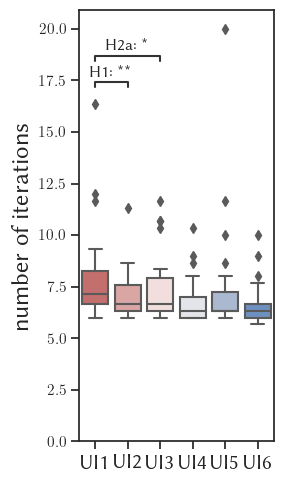

In [6]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']
labels = ['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6']
fig, ax = plt.subplots(figsize=(3, 5))
sns.boxplot(ax=ax, data=df_iterations_text, x='interface', y='iteration', order=interfaces, palette=colors, saturation=1)
ax.set_xticklabels(labels, fontsize=15)
ax.set_ylim(0, 12)
ax.set_ylabel('number of iterations', fontsize=18)
ax.set_xlabel('')
annot = Annotator(ax, [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    # ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    # ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    # ('listwise-ranking', 'listwise-notie'),  # H4c
    # ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_iterations, x='interface', y='iteration', order=interfaces, show_non_significant=True)
annot.set_custom_annotations(['H1: **', 'H2a: *'])
annot.annotate()
plt.tight_layout()
plt.savefig('figures/iterations_text.pdf', dpi=300, bbox_inches='tight')

df_iterations.groupby('interface').iteration.describe()

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pointwise vs. pairwise: H1: *
pointwise vs. listwise-rating: H2a: ***
pairwise vs. listwise-cantie: H2b: ***


,count,mean,std,min,25%,50%,75%,max
interface,,,,,,,,
listwise-cantie,180.0,7.766667,3.658769,6.0,6.0,6.0,7.0,20.0
listwise-notie,180.0,7.561111,3.307624,6.0,6.0,6.0,7.0,20.0
listwise-ranking,180.0,8.033333,3.949259,5.0,6.0,6.0,8.0,20.0
listwise-rating,179.0,7.932961,3.639048,6.0,6.0,6.0,8.0,20.0
pairwise,179.0,8.391061,3.670889,6.0,6.0,7.0,9.0,20.0
pointwise,180.0,9.566667,4.300318,6.0,6.0,8.0,11.0,20.0


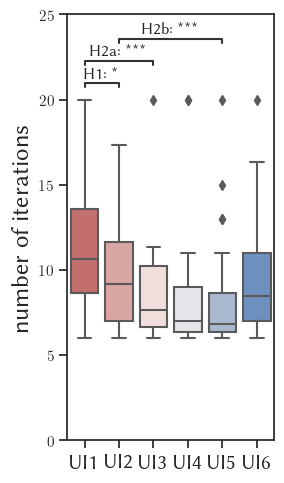

In [7]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']
labels = ['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6']
fig, ax = plt.subplots(figsize=(3, 5))
sns.boxplot(ax=ax, data=df_iterations_image, x='interface', y='iteration', order=interfaces, palette=colors, saturation=1)
ax.set_xticklabels(labels, fontsize=15)
ax.set_ylim(0, 12)
ax.set_ylabel('number of iterations', fontsize=18)
ax.set_xlabel('')
annot = Annotator(ax, [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    # ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    # ('listwise-ranking', 'listwise-notie'),  # H4c
    # ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_iterations, x='interface', y='iteration', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H1: *', 'H2a: ***', 'H2b: ***'])
annot.annotate()
plt.tight_layout()
plt.savefig('figures/iterations_image.pdf', dpi=300, bbox_inches='tight')

df_iterations.groupby('interface').iteration.describe()

In [14]:
df_listwise = df_all[df_all.interface.str.contains('listwise')]
for idx, row in df_listwise.iterrows():
    if 'listwise' in row['interface']:
        df_listwise.loc[idx, 'rankingInteraction'] = len(row.rating)
df_listwise = df_listwise[['userID', 'domain', 'taskID', 'iteration', 'interface', 'rankingInteraction']]
df_listwise.to_csv('processed/rankings.csv', index=False)
df_listwise

,userID,domain,taskID,iteration,interface,rankingInteraction
1342,P111,text,3,1,listwise-rating,4.0
1343,P111,text,3,2,listwise-rating,4.0
1344,P111,text,3,3,listwise-rating,4.0
1345,P111,text,3,4,listwise-rating,4.0
1346,P111,text,3,5,listwise-rating,4.0
...,...,...,...,...,...,...
8930,P149,image,2,2,listwise-ranking,5.0
8931,P149,image,2,3,listwise-ranking,5.0
8932,P149,image,2,4,listwise-ranking,6.0
8933,P149,image,2,5,listwise-ranking,6.0


In [15]:
df_data = df_listwise[df_listwise.interface != 'listwise-rating'].groupby(['userID', 'domain', 'interface']).mean().reset_index()
df_data

,userID,domain,interface,rankingInteraction
0,P192,image,listwise-cantie,4.576923
1,P129,text,listwise-notie,5.136364
2,P342,text,listwise-ranking,5.300000
3,P057,text,listwise-cantie,5.800000
4,P069,text,listwise-ranking,4.888889
...,...,...,...,...
175,P338,text,listwise-ranking,4.750000
176,P121,image,listwise-ranking,5.111111
177,P050,image,listwise-ranking,4.591837
178,P078,text,listwise-notie,5.894737


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

listwise-notie vs. listwise-ranking: H4c: **


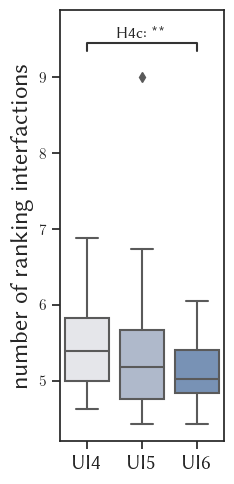

In [16]:

fig, axes = plt.subplots(1, 1, figsize=(2.5, 5))
colors = sns.color_palette('Blues', as_cmap=False, n_colors=3)
colors = ['#e4e5eb', '#aab8d0', '#6e90bf']
sns.boxplot(ax=axes, data=df_data[df_data.domain == 'text'], x='interface', y='rankingInteraction', palette=colors, order=['listwise-notie', 'listwise-cantie', 'listwise-ranking'])
# axes.set_ylim(4, 6)
# set ytick labels from 4 to 6
# axes.set_yticks([4, 5, 6])
annot = Annotator(axes, [
    # ('pointwise', 'pairwise'),               # H1
    # ('pointwise', 'listwise-rating'),        # H2a
    # ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    # ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    ('listwise-ranking', 'listwise-notie'),  # H4c
    # ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_listwise, x='interface', y='rankingInteraction', order=['listwise-notie', 'listwise-cantie', 'listwise-ranking'], show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H4c: **'])
annot.annotate()
axes.set_xlabel('')
axes.set_ylabel('number of ranking interfactions', fontsize=18)
axes.set_xticklabels(['UI4', 'UI5', 'UI6'], fontsize=15)
plt.tight_layout()
plt.savefig('figures/rankings_text.pdf', bbox_inches='tight')

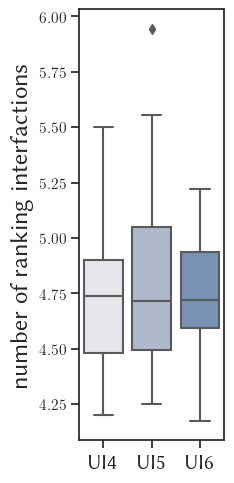

In [20]:

fig, axes = plt.subplots(1, 1, figsize=(2.5, 5))
colors = sns.color_palette('Blues', as_cmap=False, n_colors=3)
colors = ['#e4e5eb', '#aab8d0', '#6e90bf']
sns.boxplot(ax=axes, data=df_data[df_data.domain == 'image'], x='interface', y='rankingInteraction', palette=colors, order=['listwise-notie', 'listwise-cantie', 'listwise-ranking'])
# axes.set_ylim(4, 6)
# set ytick labels from 4 to 6
# axes.set_yticks([4, 5, 6])
# annot = Annotator(axes, [
#     # ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     # ('listwise-ranking', 'pairwise'),        # H4a
#     # ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     # ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_listwise, x='interface', y='rankingInteraction', order=['listwise-notie', 'listwise-cantie', 'listwise-ranking'], show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
# annot.set_custom_annotations(['H4c: **'])
# annot.annotate()
axes.set_xlabel('')
axes.set_ylabel('number of ranking interfactions', fontsize=18)
axes.set_xticklabels(['UI4', 'UI5', 'UI6'], fontsize=15)
plt.tight_layout()
plt.savefig('figures/rankings_image.pdf', bbox_inches='tight')